In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR  = Path("../challenge_data")
TRAIN_OBS = 110
TEST_OBS  = 24

In [4]:
meta = pd.read_csv(DATA_DIR / "vm_metadata.csv")
cpu  = pd.read_csv(
    DATA_DIR / "vm_cpu_readings.csv",
    dtype={"timestamp": "int64", "vm_id": "str",
           "min_cpu": "float64", "max_cpu": "float64", "avg_cpu": "float64"},
)

print(f"vm_metadata    : {meta.shape[0]:,} rows x {meta.shape[1]} cols")
print(f"vm_cpu_readings: {cpu.shape[0]:,} rows x {cpu.shape[1]} cols")

vm_metadata    : 10,000 rows x 11 cols
vm_cpu_readings: 1,340,000 rows x 5 cols


In [5]:
meta.head(3)

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4


In [6]:
cpu.head(3)

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588


## 2. Build aggregate time-series targets

For each timestamp `t`:
- **`active_vm_count`** — number of distinct VM IDs with a valid CPU observation at `t`
- **`aggregate_cpu_utilization`** — mean of VM-level `avg_cpu` values at `t` (expressed as % in [0, 100])

In [7]:
targets = (
    cpu.groupby("timestamp")
    .agg(
        active_vm_count          =("vm_id",   "nunique"),
        aggregate_cpu_utilization=("avg_cpu", "mean"),
    )
    .reset_index()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print(f"Total observations : {len(targets)}")
print(f"Timestamp range    : {targets['timestamp'].min()} - {targets['timestamp'].max()} s")
print(f"Step size (seconds): {targets['timestamp'].diff().dropna().unique()}")
targets

Total observations : 134
Timestamp range    : 0 - 39900 s
Step size (seconds): [300.]


,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383
3,900,10000,9.224419
4,1200,10000,9.143503
...,...,...,...
129,38700,10000,9.430236
130,39000,10000,9.307138
131,39300,10000,9.499973
132,39600,10000,9.423042


## 3. Train / test split  (110 train | 24 test)

The **first 110 observations** form the training window; the **final 24 observations**
are the 2-hour holdout horizon. No shuffling — strictly chronological.

In [8]:
assert len(targets) == TRAIN_OBS + TEST_OBS, (
    f"Expected {TRAIN_OBS + TEST_OBS} observations, got {len(targets)}"
)

train = targets.iloc[:TRAIN_OBS].copy()
test  = targets.iloc[TRAIN_OBS:].copy()

print(f"Train : {len(train)} obs  (t = {train['timestamp'].iloc[0]} - {train['timestamp'].iloc[-1]} s)")
print(f"Test  : {len(test)} obs   (t = {test['timestamp'].iloc[0]} - {test['timestamp'].iloc[-1]} s)")

Train : 110 obs  (t = 0 - 32700 s)
Test  : 24 obs   (t = 33000 - 39900 s)


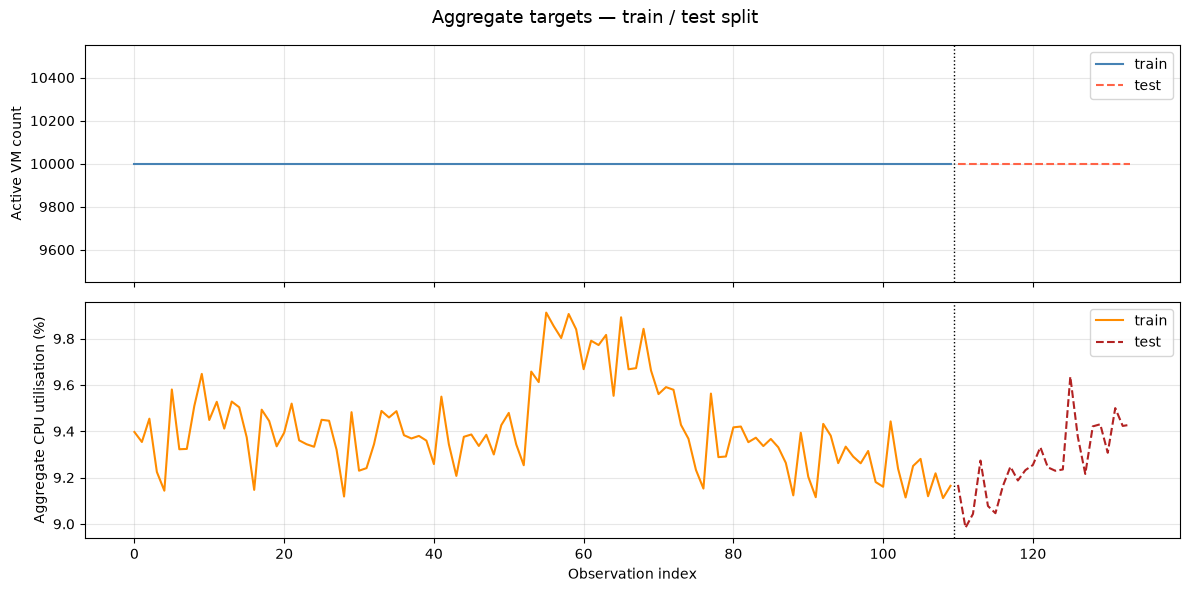

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
fig.suptitle("Aggregate targets — train / test split", fontsize=13)

for ax, col, label, c_train, c_test in zip(
    axes,
    ["active_vm_count", "aggregate_cpu_utilization"],
    ["Active VM count", "Aggregate CPU utilisation (%)"],
    ["steelblue", "darkorange"],
    ["tomato",    "firebrick"],
):
    ax.plot(train.index, train[col], color=c_train, label="train")
    ax.plot(test.index,  test[col],  color=c_test,  label="test",  linestyle="--")
    ax.axvline(TRAIN_OBS - 0.5, color="black", linewidth=1, linestyle=":")
    ax.set_ylabel(label)
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Observation index")
plt.tight_layout()
plt.show()